# 1.02 · MiBici data cleaning

**Phase 1 (data cleaning)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`.

- **Input:** `data/interim/mibici/` (typed Parquet with a single schema, see notebook `1.01`).
- **Output:** `data/processed/mibici/` (same layout and schema, values cleaned) plus `cleaning_report.json`.
- **Scope:** value quality only. Data contract tests → cleaning rules → missing data strategy → validation → `data/processed`. The exploratory analysis of the clean data is notebook `1.03`, which reads only `data/processed`: changing a cleaning decision means editing `interim_data_cleaning`, re-running this notebook, then re-running `1.03`.

There is no clean "original" to compare against: every decision is justified with the data itself and with MiBici's operating rules. The cleaning decisions live in `team2_mlops2026.data.interim_data_cleaning`; data access and trip metrics in `team2_mlops2026.data.trip_data`; tables in `team2_mlops2026.eda` and charts in `team2_mlops2026.plots`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from team2_mlops2026 import eda, plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.data.interim_data_cleaning import (
    MAX_AGE,
    MAX_DURATION_S,
    MAX_SPEED_KMH,
    MIN_AGE,
    MIN_DURATION_S,
    PROFILE_COLUMNS,
    CleaningLog,
    build_user_profiles,
    clean_tracked,
    drop_duplicates,
    drop_incomplete_demographics,
    drop_invalid_trips,
    impute_from_profiles,
    impute_global,
    invalidate_demographics,
    overlapping_trips,
    report_totals,
    rule_violations,
    validate,
)
from team2_mlops2026.data.trip_data import (
    BIRTH_YEAR,
    DEMOGRAPHIC_COLUMNS,
    PROCESSED_MIBICI_DIR,
    age_at_trip,
    load_stations,
    load_trips,
    trip_files,
    trip_metrics,
)

pd.set_option("display.max_columns", 50)
plots.use_style()

2026-10-24 11:51:42.926 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: C:\MLOpsRepos\Proyecto\team2_mlops2026


## Parameters

Every test and comparison uses all trips.

In [3]:
WORKERS = 4  # parallel processes when writing data/processed
FORCE = False  # True = re-clean even if data/processed is up to date

## 1. Load the interim data

In [4]:
trips = load_trips()
stations = load_stations()
print(f"Trips: {len(trips):,} rows x {trips.shape[1]} columns "
      f"({trips.memory_usage(deep=True).sum() / 2**30:.2f} GB in memory)")
print(f"Period: {trips['Inicio_del_viaje'].min()} -> {trips['Inicio_del_viaje'].max()}")
print(f"Stations in the latest nomenclature: {len(stations)}")
trips.head()

Trips: 39,078,984 rows x 8 columns (2.26 GB in memory)
Period: 2014-12-01 00:33:47 -> 2026-09-30 23:59:48
Stations in the latest nomenclature: 484


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,4601,10324,M,<NA>,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47
1,4604,10324,M,<NA>,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5
2,4628,3,F,1990,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79
3,4631,102,M,1982,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79
4,4632,3,F,1990,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79


## 2. Structure and data quality

Types were fixed in `1.01`; what remains are the values. The contract is written on four derived quantities: trip duration, straight-line distance between stations, the implied speed, and the rider's age at trip time.

In [5]:
eda.data_quality(trips)

,dtype,missing,missing_pct,n_unique
Viaje_Id,Int64,0,0.000000,39078226
Usuario_Id,Int64,0,0.000000,109863
Genero,category,144508,0.369784,2
Año_de_nacimiento,Int64,81651,0.208938,91
Inicio_del_viaje,datetime64[ms],0,0.000000,34054618
Fin_del_viaje,datetime64[ms],0,0.000000,33927919
Origen_Id,Int64,0,0.000000,486
Destino_Id,Int64,0,0.000000,486


In [6]:
metrics = trip_metrics(trips, stations)
eda.univariate_summary(metrics)

,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
duration_s,39078984.0,864.485168,45595.691406,0.0,344.000000,565.000000,881.000000,3.775373e+07,565.000000,305.086456,113744.671875
age,38997333.0,33.394165,15.139389,0.0,26.000000,30.000000,39.000000,2.021000e+03,30.000000,65.186852,8225.731445
speed_kmh,39019911.0,11.369763,129.640091,0.0,6.433741,8.734135,10.854300,2.357237e+04,8.734135,59.439262,4373.855469
distance_km,39074948.0,1.466471,1.087105,0.0,0.694106,1.231208,2.015786,1.372290e+01,1.231208,1.246949,2.157604


**Result → action.** The types are right; the values are not. The summary exposes impossible records: durations up to 3.8·10⁷ s (437 days), ages from 0 to 2,021 years and speeds up to 23,572 km/h. They dominate the means, standard deviations and skewness (305 for duration), so no EDA is meaningful before the contract below is enforced. Distance is the only well-behaved quantity because it comes from the station list, not from timestamps or typed values.

## 3. Data contract tests

Each test checks one property, shows the evidence and ends in an action. The bounds live as constants in `interim_data_cleaning`:

| Rule | Contract | Action | Test |
|---|---|---|---|
| Unique trips | no exact duplicates, unique `Viaje_Id` | drop the row | T3 |
| Gender | `M`, `F` or missing | value → `<NA>` | T4 |
| Age at trip time | 16-90 years | value → `<NA>` | T5 |
| Duration | 60 s - 24 h | drop the row | T7 |
| Speed between stations | ≤ 30 km/h | drop the row | T8 |

A rule on the trip itself (it did not happen as recorded) drops the row. A rule on a rider attribute only invalidates that value: the trip is still real demand.

### T1 — Schema test
**What it checks:** that every interim month shares one Parquet schema.
**Why it matters:** the rest of the tests read all months as one table.

In [7]:
schemas = pd.Series({p.name: pq.read_schema(p).remove_metadata().to_string() for p in trip_files()})
print(f"{len(schemas)} interim files -> {schemas.nunique()} distinct schema(s)")

142 interim files -> 1 distinct schema(s)


**Result → action.** One schema for all 142 months → the whole history can be read as a single table; no action. `validate` re-checks the columns of every cleaned month.

### T2 — Key and required-field test
**What it checks:** that identifiers and timestamps are present and coherent.
**Why it matters:** a trip without an origin, a user or a start time cannot be counted as demand, and a model cannot be joined back to it.

In [8]:
id_columns = ["Viaje_Id", "Usuario_Id", "Origen_Id", "Destino_Id"]
pd.Series({
    "nulls in required columns": int(trips.drop(columns=list(DEMOGRAPHIC_COLUMNS)).isna().sum().sum()),
    "non-positive ids": int((trips[id_columns] <= 0).sum().sum()),
    "end before start": int((trips["Fin_del_viaje"] < trips["Inicio_del_viaje"]).sum()),
    "repeated Viaje_Id": int(trips["Viaje_Id"].duplicated().sum()),
}).to_frame("trips")

,trips
nulls in required columns,0
non-positive ids,0
end before start,0
repeated Viaje_Id,758


**Result → action.** No nulls, no non-positive ids and no trip ending before it starts. The only key problem is 758 repeated `Viaje_Id` → analyzed in T3.

### T3 — Duplicate test
**What it checks:** exact duplicate rows and whether every repeated `Viaje_Id` is one of them.
**Why it matters:** duplicates inflate demand and can leak between train and test splits. A repeated id with *different* content would be a conflict that cannot be resolved by dropping.

In [9]:
duplicated = trips.duplicated()
print(f"Exact duplicate rows: {duplicated.sum():,}")
print(f"Repeated Viaje_Id that are not exact duplicates: {trips['Viaje_Id'].duplicated().sum() - duplicated.sum():,}")
trips.loc[duplicated, "Inicio_del_viaje"].dt.to_period("M").value_counts().to_frame("duplicate rows")

Exact duplicate rows: 758


Repeated Viaje_Id that are not exact duplicates: 0


,duplicate rows
Inicio_del_viaje,
2026-09,758


**Result → action.** All 758 repeated ids are exact copies of another row, and all of them are in the most recent file (2026-09): a publication glitch, not conflicting records → **drop exact duplicates**. `Viaje_Id` uniqueness becomes part of the contract, so a future repeated id with *different* content fails loudly instead of being silently dropped.

### T4 — Categorical domain test (`Genero`)
**What it checks:** the values present in the only categorical column.
**Why it matters:** unexpected codes or placeholders (`?`, `X`, `N/A`) must be listed explicitly so a new one is noticed next time.

In [10]:
gender_counts = trips["Genero"].value_counts(dropna=False)
gender_counts.to_frame("trips").assign(pct=gender_counts / len(trips) * 100)

,trips,pct
Genero,,
M,28628237,73.257373
F,10306239,26.372843
NaN,144508,0.369784


**Result → action.** Only `M`, `F` and missing; no placeholder codes. 73% of the trips are by men. 144,508 trips (0.37%) have no gender → handled in section 5. The rule `Genero ∈ {M, F}` stays in the contract so that a new code is caught.

### T5 — Birth year plausibility test
**What it checks:** the age implied by `Año_de_nacimiento` at the time of each trip.
**Why it matters:** the birth year is typed by the user at registration. MiBici registers riders from 16 years old (16-17 with a guardian), so younger ages are impossible, and very old ones are usually placeholder years.

In [11]:
age_bins = pd.cut(metrics["age"], [-np.inf, 0, 9, 14, 15, 17, 69, 79, 90, 100, np.inf])
age_bins.value_counts(sort=False, dropna=False).to_frame("trips")

,trips
age,
"(-inf, 0.0]",569
"(0.0, 9.0]",1532
"(9.0, 14.0]",79
"(14.0, 15.0]",30
"(15.0, 17.0]",101308
"(17.0, 69.0]",38745693
"(69.0, 79.0]",130316
"(79.0, 90.0]",11427
"(90.0, 100.0]",1916


In [12]:
too_old = trips.loc[metrics["age"] > MAX_AGE, BIRTH_YEAR]
too_young = trips.loc[metrics["age"] < MIN_AGE, BIRTH_YEAR]
print(f"Ages > {MAX_AGE}: {len(too_old):,} trips from {trips.loc[too_old.index, 'Usuario_Id'].nunique()} users")
print(f"Ages < {MIN_AGE}: {len(too_young):,} trips from {trips.loc[too_young.index, 'Usuario_Id'].nunique()} users")
pd.concat({"too old": too_old.value_counts().head(8), "too young": too_young.value_counts().head(8)}, axis=1)

Ages > 90: 6,379 trips from 12 users
Ages < 16: 2,210 trips from 24 users


,too old,too young
Año_de_nacimiento,,
1920,2881,<NA>
1918,1228,<NA>
1922,769,<NA>
1,747,<NA>
199,316,<NA>
1917,206,<NA>
200,189,<NA>
1924,40,<NA>
2023,<NA>,1151


**Result → action.** The ages have a clear floor at 16 (30 trips at 15 vs 101,308 at 16-17) that matches MiBici's registration rule. The "too old" values are placeholder-like years (1920, 1918, 1922, 1917) or typos (1, 199, 200), and the "too young" ones are years after any possible registration (2021-2023). They come from very few accounts (12 and 24 users), so they are entry errors, not rare riders → **set the birth year to missing when the age at trip time is outside 16-90**, and keep the trip. Ages 80-90 (11,427 trips) are improbable but not impossible, so they stay.

### T6 — Missing-value test
**What it checks:** missing values per column and how they evolve over time.
**Why it matters:** the amount and *pattern* of missingness decides whether dropping rows is harmless or biased (analyzed in section 5).

In [13]:
missing = trips[list(DEMOGRAPHIC_COLUMNS)].isna()
year = trips["Inicio_del_viaje"].dt.year
print(f"Trips missing gender only: {(missing['Genero'] & ~missing[BIRTH_YEAR]).sum():,}")
print(f"Trips missing birth year only: {(~missing['Genero'] & missing[BIRTH_YEAR]).sum():,}")
print(f"Trips missing both: {missing.all(axis=1).sum():,}")
missing_by_year = (missing.groupby(year).mean() * 100).add_suffix(" missing (%)")
missing_by_year.insert(0, "trips", year.value_counts().sort_index())
missing_by_year

Trips missing gender only: 133,969
Trips missing birth year only: 71,112
Trips missing both: 10,539


,trips,Genero missing (%),Año_de_nacimiento missing (%)
Inicio_del_viaje,,,
2014,23967,0.020862,0.917929
2015,469871,0.050227,0.801284
2016,941918,0.021976,0.759089
2017,2516534,0.000000,0.506729
2018,3403485,0.000000,0.341444
2019,4636652,0.138354,0.248498
2020,2866072,0.116850,0.120269
2021,3184410,0.151739,0.136038
2022,4202942,0.431936,0.377402


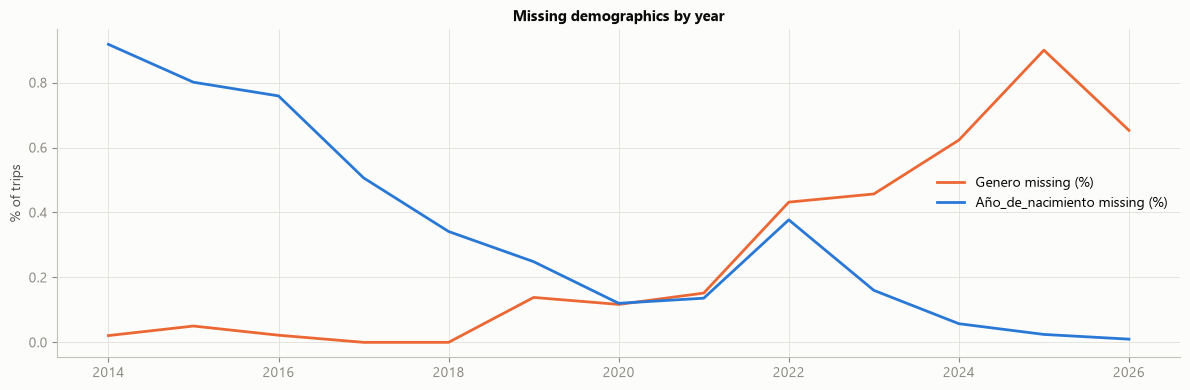

In [14]:
plots.plot_lines(missing_by_year.drop(columns="trips"), "Missing demographics by year", "% of trips");

**Result → action.** Missingness is small (0.37% gender, 0.21% birth year, rarely both), but **it is not stable over time**: missing birth year fell from 0.9% in 2014 to 0.01% in 2026, while missing gender grew from 0% (2017-2018) to 0.9% in 2025. A pattern that drifts with time is the first sign that the data is not missing completely at random → section 5 tests the mechanism before choosing a strategy.

### T7 — Duration range test
**What it checks:** the distribution of `Fin_del_viaje - Inicio_del_viaje`, with the share of trips that return to their origin station.
**Why it matters:** bike-share operators publish their data without trips under 60 s, which are false starts or riders re-docking a bike to make sure it is locked ([Divvy](https://divvybikes.com/system-data), [Citi Bike](https://citibikenyc.com/system-data)). MiBici trips are limited to 30 min (45 on Sundays) and charge for the extra time, so long trips are legitimate, but a loan over a day is a bike that was not docked, not a trip.

In [15]:
same_station = trips["Origen_Id"] == trips["Destino_Id"]
duration_bins = pd.cut(
    metrics["duration_s"],
    [-np.inf, 0, 30, MIN_DURATION_S, 120, 1800, 3600, 3 * 3600, MAX_DURATION_S, np.inf],
    right=False,
)
pd.DataFrame({
    "trips": duration_bins.value_counts(sort=False),
    "same_station_pct": same_station.groupby(duration_bins, observed=False).mean() * 100,
})

,trips,same_station_pct
duration_s,,
"[-inf, 0.0)",0,<NA>
"[0.0, 30.0)",1024572,94.275659
"[30.0, 60.0)",244853,97.922427
"[60.0, 120.0)",509475,28.798862
"[120.0, 1800.0)",36682078,3.513847
"[1800.0, 3600.0)",563517,12.804405
"[3600.0, 10800.0)",40647,23.426083
"[10800.0, 86400.0)",12010,16.994172
"[86400.0, inf)",1832,5.786026


**Result → action.**
- 1,269,425 trips (3.2%) last under 60 s and 94-98% of them return to their origin station: re-docks and false starts, not travel → **drop trips under 60 s**. From 60 s on, round trips fall to 29% and then to the 3.5% typical of real trips, which confirms the cut point.
- 1,832 loans exceed 24 h (up to 437 days): bikes not docked or system errors → **drop trips over 24 h**.
- The 616k trips between 30 min and 24 h are kept: MiBici charges for the extra time, so they are real, if unusual.

### T8 — Cross-field consistency tests
**What they check:**
1. *Speed:* the distance between the two stations divided by the duration. The straight line is shorter than any real route, so this speed is a lower bound of the real one.
2. *Referential integrity:* station ids missing from the nomenclature (their distance cannot be computed).
3. *User profile:* users whose gender or birth year changes between trips.
4. *User timeline:* a user starting a trip before their previous one ended.

**Why they matter:** single-column checks cannot catch a duration that is plausible alone but impossible for the distance covered.

In [16]:
speed = metrics.loc[~same_station, "speed_kmh"]
print("Speed quantiles between different stations (km/h):")
print(speed.quantile([0.5, 0.9, 0.99, 0.995, 0.999, 0.9999]).round(1).to_string())
pd.Series({f"> {v} km/h": int((speed > v).sum()) for v in (20, 25, MAX_SPEED_KMH, 40, 60)}).to_frame("trips")

Speed quantiles between different stations (km/h):


0.5000       9.000000
0.9000      13.100000
0.9900      17.200001
0.9950      18.500000
0.9990      66.000000
0.9999    7114.700195


,trips
> 20 km/h,103414
> 25 km/h,60701
> 30.0 km/h,52842
> 40 km/h,43657
> 60 km/h,37209


In [17]:
known = stations["id"]
unknown_station = ~trips["Origen_Id"].isin(known) | ~trips["Destino_Id"].isin(known)
unknown_ids = trips.loc[unknown_station, ["Origen_Id", "Destino_Id"]].stack().loc[lambda s: ~s.isin(known)]
print(f"Trips touching a station missing from the nomenclature: {unknown_station.sum():,}, ids {sorted(unknown_ids.unique())}")
year[unknown_station].value_counts().sort_index().to_frame("trips")

Trips touching a station missing from the nomenclature: 4,036, ids [np.int64(124), np.int64(405), np.int64(407)]


,trips
Inicio_del_viaje,
2016,23
2017,24
2018,2
2019,26
2020,7
2026,3954


In [18]:
changes = trips.groupby("Usuario_Id")[list(DEMOGRAPHIC_COLUMNS)].nunique().gt(1).sum()
print(f"Users: {trips['Usuario_Id'].nunique():,}")
print(f"Users with more than one gender: {changes['Genero']:,}; with more than one birth year: {changes[BIRTH_YEAR]:,}")
overlap = overlapping_trips(trips)
print(f"Trips starting before the same user's previous trip ended: {overlap.sum():,} ({overlap.mean():.3%})")

Users: 109,863
Users with more than one gender: 12; with more than one birth year: 405


Trips starting before the same user's previous trip ended: 24,215 (0.062%)


**Result → action.**
1. *Speed:* p99.5 is 18.5 km/h, but p99.9 jumps to 66 km/h and p99.99 to 7,115 km/h. There is no continuum between real cycling and these records. 52,842 trips (0.14%) exceed 30 km/h even on the straight line, which already understates the real speed → **drop trips faster than 30 km/h**.
2. *Stations:* ids 124, 405 and 407 are not in the current nomenclature (4,036 trips, 98% of them in 2026). The trips are real demand → **keep them**. Their distance and speed are unknown, so the speed rule cannot judge them. Features that need coordinates will need a station history, not only the latest snapshot.
3. *Profiles:* 12 users have two genders and 405 have several birth years → a user's most frequent valid value is the natural profile for recovering missing values (section 5).
4. *Timeline:* 24,215 trips (0.06%) start before the same user's previous trip ended. The data cannot tell which of the two is wrong → **diagnostic only**, re-checked after cleaning.

### T9 — Contract summary
**What it checks:** every rule at once, on the interim data.
**Why it matters:** it is the baseline for the cleaning log: after cleaning, every count must be zero.

In [19]:
violations = rule_violations(trips, metrics)
print(f"Rows breaking at least one trip rule (duplicate, duration, speed): "
      f"{violations[['duplicate', 'too_short', 'too_long', 'too_fast']].any(axis=1).sum():,}")
violations.sum().to_frame("trips").assign(pct=lambda d: d["trips"] / len(trips) * 100)

Rows breaking at least one trip rule (duplicate, duration, speed): 1,292,098


,trips,pct
duplicate,758,0.001940
too_short,1269425,3.248357
too_long,1832,0.004688
too_fast,52842,0.135218
invalid_gender,0,0.000000
invalid_age,8589,0.021979


**Result → action.** 1,292,098 rows (3.3%) break a trip rule, almost all of them the under-60 s re-docks; 8,589 birth years break the age rule. The rules overlap (a 5 s trip between two stations is also too fast), so the cleaning log below reports what each step actually removes.

## 4. Cleaning pipeline

Each test maps to one pure step in `interim_data_cleaning` (frame in → new frame out, optional `CleaningLog`). The same steps run per month in `clean()` to write `data/processed`, so the notebook and the pipeline cannot drift apart.

User profiles (the most frequent *valid* gender and birth year of each user) are built from every interim trip, false starts included: a rider's attributes do not depend on whether one particular loan was valid.

In [20]:
profiles = build_user_profiles(trips[list(PROFILE_COLUMNS)])

log = CleaningLog()
base = (
    trips
    .pipe(drop_duplicates, log=log)
    .pipe(drop_invalid_trips, stations, log=log)
    .pipe(invalidate_demographics, log=log)
)
del trips, metrics, violations, missing, year, duplicated, same_station, duration_bins
del age_bins, speed, unknown_station, overlap, too_old, too_young
gc.collect()

print(f"Users with a profile: {len(profiles):,}")
log.to_frame()

Users with a profile: 107,352


,step,detail,rows_before,rows_after,rows_removed,cells_changed
0,drop_duplicates,exact duplicate rows,39078984,39078226,758,0
1,drop_invalid_trips,"rules overlap: too_short=1,269,408, too_long=1...",39078226,37786886,1291340,0
2,invalidate_demographics,"invalid_gender=0, invalid_age=8,245",37786886,37786886,0,8245


## 5. Missing data strategy

After invalidation every remaining problem is the same one: missing `Genero` or `Año_de_nacimiento`. How it is handled matters for every later stage: it decides which trips exist for demand modelling and which values the demographic features carry.

### 5.1 How much is missing

In [21]:
missing = base[list(DEMOGRAPHIC_COLUMNS)].isna()
missing["any"] = missing.any(axis=1)
missing.agg(["sum", "mean"]).T.rename(columns={"sum": "trips", "mean": "share"})

,trips,share
Genero,139019.0,0.003679
Año_de_nacimiento,85852.0,0.002272
any,213672.0,0.005655


### 5.2 Missingness mechanism

Listwise deletion is only unbiased when values are *missing completely at random* (MCAR). Cramér's V measures how much missingness depends on each grouping (0 = independent). With 39M rows any chi-square p-value is 0, so the effect size is what matters.

In [22]:
start = base["Inicio_del_viaje"]
eda.missingness_association(
    missing,
    {
        "year": start.dt.year,
        "hour": start.dt.hour,
        "weekday": start.dt.dayofweek,
        "origin station": base["Origen_Id"],
        "user": base["Usuario_Id"],
    },
)

,year,hour,weekday,origin station,user
Genero,0.049140,0.010678,0.009808,0.041707,0.965231
Año_de_nacimiento,0.036867,0.021639,0.038756,0.040866,0.965172
any,0.032721,0.015809,0.027898,0.040925,0.963408


In [23]:
incomplete_users = base.loc[missing["any"], "Usuario_Id"]
print(f"Incomplete trips: {missing['any'].sum():,}, from {incomplete_users.nunique():,} users "
      f"({incomplete_users.nunique() / base['Usuario_Id'].nunique():.1%} of all users)")
print(f"The 10 heaviest of those users account for "
      f"{incomplete_users.value_counts().head(10).sum() / len(incomplete_users):.1%} of the incomplete trips")
for col in DEMOGRAPHIC_COLUMNS:
    recoverable = missing[col] & base["Usuario_Id"].isin(profiles.index[profiles[col].notna()])
    print(f"{col}: {recoverable.sum():,} of {missing[col].sum():,} missing values recoverable from the user's own trips")

Incomplete trips: 213,672, from 11,874 users (10.8% of all users)
The 10 heaviest of those users account for 8.7% of the incomplete trips


Genero: 25,432 of 139,019 missing values recoverable from the user's own trips


Año_de_nacimiento: 12,263 of 85,852 missing values recoverable from the user's own trips


**Result → action.** Missingness barely depends on year, hour, weekday or station (V ≤ 0.05), but it is **almost entirely determined by the user (V ≈ 0.96)**. Gender and birth year are account attributes: they are missing for 11,874 accounts (10.8% of users), and then for all of those accounts' trips. The data is therefore *not* MCAR. Listwise deletion removes whole riders, and the stations and months those riders use lose demand. Only 25,432 missing genders and 12,263 missing birth years can be recovered from the same user's other trips; the rest belong to users who never gave the value.

### 5.3 Candidate strategies

| | Strategy A — **drop rows** | Strategy B — **global mode / median** | Strategy C — **user profile** |
|---|---|---|---|
| Idea | Keep only trips with both values | Gender ← overall mode, birth year ← overall median | Fill from the same user's other trips; the rest stays `<NA>` |
| Pros | Every value is real | Keeps every row, no missing values | Keeps every row; every filled value is the rider's own |
| Cons | Removes trips, biased if not MCAR | Invents values; hides that they were missing | Leaves some `<NA>` for the model pipeline |

Strategies run on the demographic columns only (`PROFILE_COLUMNS`) to keep memory bounded; they never touch the trip columns.

In [24]:
demographics = base[list(PROFILE_COLUMNS)]
strategies = {
    "A - drop rows": drop_incomplete_demographics(demographics),
    "B - global fill": impute_global(demographics),
    "C - user profile": impute_from_profiles(demographics, profiles),
}
pd.DataFrame({
    name: {
        "rows": len(d),
        "rows_kept_pct": len(d) / len(base) * 100,
        "missing_gender": int(d["Genero"].isna().sum()),
        "missing_birth_year": int(d[BIRTH_YEAR].isna().sum()),
    }
    for name, d in strategies.items()
}).T

,rows,rows_kept_pct,missing_gender,missing_birth_year
A - drop rows,37573214.0,99.434534,0.0,0.0
B - global fill,37786886.0,100.000000,0.0,0.0
C - user profile,37786886.0,100.000000,113587.0,74020.0


### 5.4 Effect on demand (what strategy A removes)

B and C keep every trip, so trip counts are unchanged by construction. For A, the question is *where* the removed trips come from.

In [25]:
kept_a = pd.Series(base.index.isin(strategies["A - drop rows"].index), index=base.index)
month = start.dt.to_period("M")
loss_month = eda.group_loss(month, kept_a)
loss_station = eda.group_loss(base["Origen_Id"], kept_a)
pd.DataFrame({
    "by month": loss_month.describe(),
    "by origin station": loss_station.describe(),
    "by hour": eda.group_loss(start.dt.hour, kept_a).describe(),
}).T.drop(columns="count").round(2)

,mean,std,min,25%,50%,75%,max
by month,0.58,0.28,0.06,0.35,0.61,0.78,1.19
by origin station,0.62,0.65,0.00,0.29,0.48,0.74,6.12
by hour,0.97,1.19,0.00,0.50,0.60,0.73,4.82


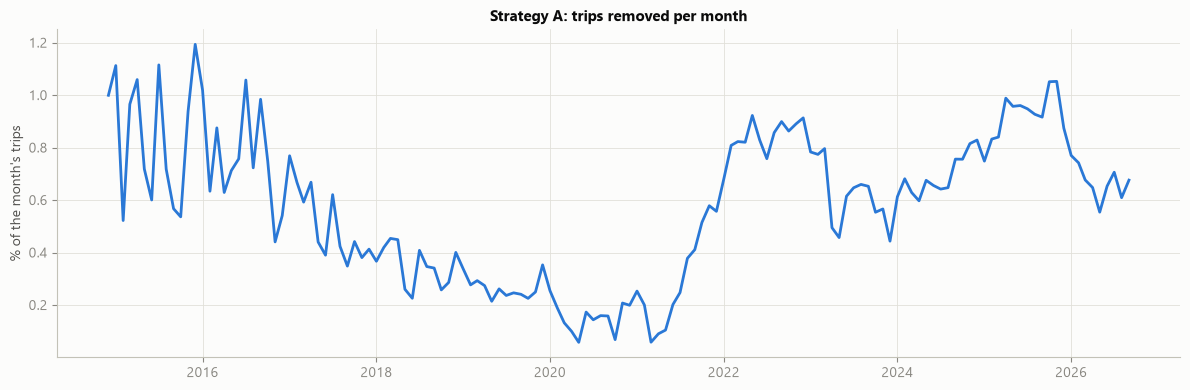

In [26]:
plots.plot_lines(loss_month.to_timestamp().to_frame("removed"), "Strategy A: trips removed per month", "% of the month's trips");

In [27]:
loss_station.nlargest(10).to_frame("removed_pct").join(
    stations.set_index("id")["name"]
).join(base["Origen_Id"].value_counts().rename("trips"))

,removed_pct,name,trips
Origen_Id,,,
517,6.117021,(ZPN-106) Av. Atemajac/Colinas del Capitolio,376
338,5.411125,(GDL-258) Manuel Doblado / Dionisio Rodriguez,9924
446,4.604052,(GDL-305) C. Huicholes / Av. México,543
116,4.054054,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,74
506,3.384615,(GDL-288) C. Pompeya / Av. Rubén Darío,1300
239,3.372459,(GDL-172) C. Chamizal / Av. Rio Nilo,23514
340,3.182633,(ZPN-069)Jesús María Romo /Av. Aurelio Ortega,21743
343,3.059273,(ZPN-074) C. Doctores / Av. San Luis Gonzaga,7322
389,3.026469,(ZPN-014) Av. D / San Jorge,10276


In [28]:
base_metrics = trip_metrics(base, stations).drop(columns="age").assign(
    hour=start.dt.hour, weekday=start.dt.dayofweek
)
eda.distribution_tests(base_metrics, base_metrics[kept_a]).round(4)

,ks_stat,smd,variance_ratio,equivalent
feature,,,,
duration_s,0.0006,-0.0024,0.9664,True
distance_km,0.0001,-0.0001,0.9997,True
speed_kmh,0.0007,0.0015,0.9989,True
hour,0.0003,-0.0002,1.0004,True
weekday,0.0007,-0.0014,0.9985,True


**Result → action.** Globally, strategy A is harmless: the distributions of duration, distance, speed, hour and weekday do not move (KS ≤ 0.001). Locally it is not. A removes up to 1.2% of a month's trips, concentrated in 2015-2016 and 2022-2025, and up to 6.1% of a station's trips (3-5% for several busy ones, e.g. GDL-172 with 23k trips). The 4.8% maximum by hour belongs to hours 1-4, when the system is practically closed (about 560 trips in total). For a demand model trained on station × time counts, this is a systematic under-count exactly where these riders travel → **do not drop trips for missing demographics**.

### 5.5 Effect on demographics

The reference for the demographic distributions is the set of *observed* values (strategy A): it is the only information that is certainly real.

In [29]:
female_share = pd.concat(
    {
        name: eda.share_by_group(d["Genero"], d["Inicio_del_viaje"].dt.year, include_missing=False)["F"]
        for name, d in strategies.items()
    },
    axis=1,
)
female_share.round(2)

,A - drop rows,B - global fill,C - user profile
Inicio_del_viaje,,,
2014,18.01,17.83,17.83
2015,22.61,22.42,22.43
2016,23.17,23.00,23.00
2017,24.52,24.39,24.39
2018,25.29,25.20,25.20
2019,25.65,25.59,25.62
2020,26.07,26.03,26.06
2021,27.00,26.98,27.02
2022,26.90,26.80,26.88


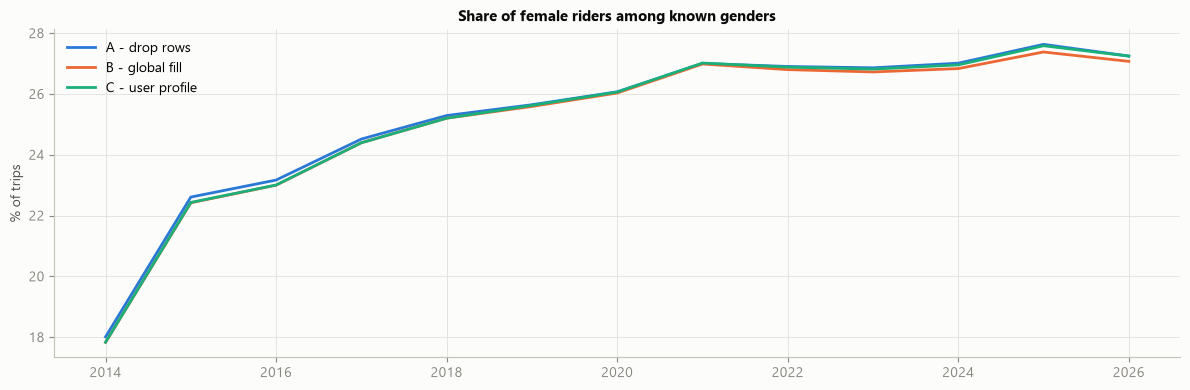

In [30]:
plots.plot_lines(female_share, "Share of female riders among known genders", "% of trips");

In [31]:
ages = {name: (d["Inicio_del_viaje"].dt.year - d[BIRTH_YEAR]).astype("float64").to_frame("age")
        for name, d in strategies.items()}
reference = ages["A - drop rows"]
age_tests = pd.concat({name: eda.distribution_tests(reference, a) for name, a in ages.items()})
age_tests.round(4)

,,ks_stat,smd,variance_ratio,equivalent
,feature,,,,
A - drop rows,age,0.0000,0.0000,1.000,True
B - global fill,age,0.0016,-0.0025,0.997,True
C - user profile,age,0.0008,-0.0013,0.999,True


In [32]:
scorecard = pd.DataFrame({
    name: {
        "rows_kept_pct": len(d) / len(base) * 100,
        "max_monthly_loss_pct": loss_month.max() if name.startswith("A") else 0.0,
        "max_station_loss_pct": loss_station.max() if name.startswith("A") else 0.0,
        "values_filled": int(demographics[list(DEMOGRAPHIC_COLUMNS)].isna().sum().sum()
                             - d[list(DEMOGRAPHIC_COLUMNS)].isna().sum().sum()) if len(d) == len(base) else 0,
        "max_female_share_gap_pp": (female_share[name] - female_share["A - drop rows"]).abs().max(),
        "age_ks_vs_observed": age_tests.loc[(name, "age"), "ks_stat"],
        "age_smd_vs_observed": age_tests.loc[(name, "age"), "smd"],
        "age_variance_ratio": age_tests.loc[(name, "age"), "variance_ratio"],
    }
    for name, d in strategies.items()
}).T
scorecard.round(4)

,rows_kept_pct,max_monthly_loss_pct,max_station_loss_pct,values_filled,max_female_share_gap_pp,age_ks_vs_observed,age_smd_vs_observed,age_variance_ratio
A - drop rows,99.4345,1.1935,6.117,0.0,0.000,0.0000,0.0000,1.000
B - global fill,100.0000,0.0000,0.000,224871.0,0.251,0.0016,-0.0025,0.997
C - user profile,100.0000,0.0000,0.000,37264.0,0.177,0.0008,-0.0013,0.999


### 5.6 Is the missingness itself informative?

If trips without gender behave like the rest, filling or flagging them makes no difference downstream. If they differ, the fact that the value is missing carries information that a global fill would erase. Values are group means in standard deviations from the overall mean.

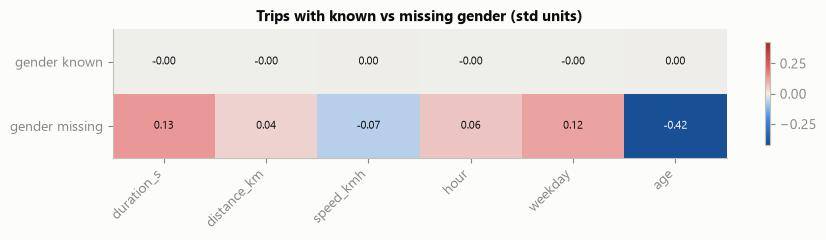

In [33]:
gender_status = missing["Genero"].map({False: "gender known", True: "gender missing"})
informative = eda.standardized_profiles(
    base_metrics.assign(age=age_at_trip(base).astype("float64")), gender_status
)
plots.plot_heatmap(informative, "Trips with known vs missing gender (std units)", diverging=True, figsize=(9, 2.5));

**Result → action.** Yes. Trips without gender come from riders who are 0.42 std younger, and their trips are longer (+0.13 std) and more often on weekends (+0.12). That gap is wider than the one between men and women on any of these measures (at most 0.23 std, notebook `1.03`). Missingness carries information: a global fill (B) would blend these riders into the majority group and erase it. Keeping `<NA>` lets the model pipeline use "unknown" as its own category.

**Decision: strategy C (user profile), with the residual values kept as `<NA>`.**
- **A is rejected.** It biases demand by station and month (up to 6.1% and 1.2%) in exchange for complete demographics.
- **B is rejected.** It keeps every trip but writes 224,871 invented values. It pushes the female share down by up to 0.25 pp in the years with most missing gender. Worse, it erases a signal: 5.6 shows that trips without gender come from a distinct group of riders.
- **C is chosen.** It keeps every trip and fills 37,264 values with the rider's own data. Its age distribution stays closest to the observed one (SMD −0.0013, variance ratio 0.999). Its small female-share gap comes from real riders being added back, not from invented values.

The 187,607 residual missing values (113,587 gender, 74,020 birth year) stay `<NA>` in `data/processed`. Any further treatment belongs to the model pipeline and must be fit on the training split only, so no test information leaks: an explicit "unknown" category plus a missing indicator, or a median.

## 6. Apply the decision and validate

The chosen strategy is applied to the full trips frame. The contract is then checked with assertions that would also run as a CI gate before training: if one fails, the pipeline stops.

In [34]:
del strategies, demographics, ages, reference, age_tests, kept_a, base_metrics, missing, recoverable
del gender_status, informative
del incomplete_users, start, month
gc.collect()

clean_trips = impute_from_profiles(base, profiles, log=log)
del base
gc.collect()

validate(clean_trips, stations)
print(f"{len(clean_trips):,} trips pass the data contract")
print("Residual missing values:", clean_trips[list(DEMOGRAPHIC_COLUMNS)].isna().sum().to_dict())
log.to_frame()

37,786,886 trips pass the data contract
Residual missing values: {'Genero': 113587, 'Año_de_nacimiento': 74020}


,step,detail,rows_before,rows_after,rows_removed,cells_changed
0,drop_duplicates,exact duplicate rows,39078984,39078226,758,0
1,drop_invalid_trips,"rules overlap: too_short=1,269,408, too_long=1...",39078226,37786886,1291340,0
2,invalidate_demographics,"invalid_gender=0, invalid_age=8,245",37786886,37786886,0,8245
3,impute_from_profiles,missing demographics <- user's own trips,37786886,37786886,0,37264


In [35]:
overlap = overlapping_trips(clean_trips)
print(f"Overlapping trips left after cleaning: {overlap.sum():,} ({overlap.mean():.3%})")

Overlapping trips left after cleaning: 16,942 (0.045%)


**Result → action.** 37,786,886 trips (96.7% of the interim rows) pass every rule, with `Viaje_Id` unique. The log accounts for every change: 758 duplicates and 1,291,340 invalid trips removed, 8,245 birth years invalidated and 37,264 values recovered from user profiles. Overlapping trips fell from 24,215 to 16,942 (0.045%), because dropping invalid loans resolved part of them. The rest stay as a known limitation for user-level features (e.g. trip sequences).

## 7. Write `data/processed` and track the run in MLflow

`clean_tracked()` runs `clean()` inside an MLflow run of the project's experiment. `clean()` runs the same steps month by month in parallel (profiles from the whole history), validates each month before writing it and records the cleaning log per file in `cleaning_report.json`. The run records:

- **Datasets:** the interim trips and the station nomenclature (inputs) and the processed trips (output), each with a digest of its files, so any change in the data shows up as a new digest.
- **Params:** the contract bounds and the missing data strategy.
- **Metrics:** the cleaning totals of `data/processed`, plus the strategy comparison of section 5 (`strategy_a_*`, `strategy_b_*`, `strategy_c_*`), which is the evidence behind the decision.
- **Artifact:** `cleaning_report.json`.

It needs the tracking server running; from the project root: `mlflow server --host 127.0.0.1 --port 5000`.

The processed data is then reloaded and validated as a whole, including `Viaje_Id` uniqueness across months.

In [36]:
n_expected = len(clean_trips)
del clean_trips, overlap
gc.collect()

strategy_metrics = {
    f"strategy_{name[0].lower()}_{metric}": float(value)
    for name, row in scorecard.iterrows()
    for metric, value in row.items()
}
summary = clean_tracked(force=FORCE, workers=WORKERS, extra_metrics=strategy_metrics)
print(f"Interim files: {summary['found']} | Cleaned: {len(summary['cleaned'])} | "
      f"Up to date: {summary['skipped']} | Failed: {len(summary['failed'])}")
print(f"MLflow run {summary['mlflow_run_id']} in experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")
if summary["failed"]:
    display(pd.DataFrame(summary["failed"]))

C:\MLOpsRepos\Proyecto\team2_mlops2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/24 12:00:23 INFO mlflow.tracking.fluent: Experiment with name 'mibici' does not exist. Creating a new experiment.


2026-10-24 12:00:25.626 | SUCCESS  | team2_mlops2026.data.interim_data_cleaning:clean:358 - Cleaning: every processed file is up to date


🏃 View run clean-interim-trips at: http://127.0.0.1:5000/#/experiments/1/runs/b4e002244bfa432b9b5d089bcdee9c6f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Interim files: 142 | Cleaned: 0 | Up to date: 142 | Failed: 0
MLflow run b4e002244bfa432b9b5d089bcdee9c6f in experiment 'mibici' (http://127.0.0.1:5000)


In [37]:
pd.Series(report_totals(), name="trips / values").to_frame()

,trips / values
files_processed,142
rows_interim,39078984
rows_processed,37786886
duplicates_removed,758
invalid_trips_removed,1291340
demographics_invalidated,8245
demographics_imputed,37264
missing_gender,113587
missing_birth_year,74020


In [38]:
trips = load_trips(PROCESSED_MIBICI_DIR)
validate(trips, stations)
print(f"Processed trips: {len(trips):,} (notebook pipeline: {n_expected:,}) -> "
      f"{'match' if len(trips) == n_expected else 'MISMATCH'}")

Processed trips: 37,786,886 (notebook pipeline: 37,786,886) -> match


## Findings and next steps

**Data quality (contract)**
- The interim data had one schema and no structural nulls, but 3.3% of its rows were not real trips: 1.27M re-docks under 60 s, 52,842 impossible speeds, 1,832 loans over 24 h and 758 duplicate rows in 2026-09.
- Birth years carry entry errors (placeholder years, typos, future years) from a handful of accounts. They are invalidated, not dropped.
- `data/processed/mibici/` holds 37,786,886 validated trips (96.7%) with the interim schema, one file per month sorted by start time, and the per-file cleaning log in `cleaning_report.json`. `python -m team2_mlops2026.data.interim_data_cleaning` reproduces it.

**Missing data decision**
- Missing demographics are a property of the *account* (Cramér's V ≈ 0.96 with the user), not random. Listwise deletion would bias station-level and monthly demand by up to 6.1% and 1.2%.
- Strategy C recovers values from the same user's trips (37,264 values) and keeps the rest as `<NA>` (113,587 gender, 74,020 birth year). Trips with missing gender come from a distinct group of riders (5.6), so the model pipeline should treat "unknown" as its own category with a missing indicator, and fit any numeric imputation on the training split only.

**Changing a decision.** Every bound and step lives in `team2_mlops2026.data.interim_data_cleaning`. After changing one, re-run this notebook with `FORCE = True` (or the CLI with `--force`) so `data/processed` is rebuilt, then re-run `1.03`, which validates its input against the same contract. Every execution is an MLflow run (`clean-interim-trips` in the project's experiment) with the contract as params and the digests of its input and output datasets, so runs before and after a change can be compared side by side.

**Known limitation.** 0.045% of the trips overlap with the same user's previous trip; the data cannot tell which of the two is wrong.